# Climatology
A climatology is an estimate of seasonal average values for a phenomenon averaged over a long period. Examples considered here are either monthly or daily (based on the day of the year). Note that the number of samples for the daily case is not very high unless some additional windowing is done around each day of the year, borrowing from neighboring days. That is what the argument nsmooth does. The following analysis uses 12 years of water temperature data and smooths over a window of 7 days.

The climatology object in this case will be a DataFrame with an integer 1-based index representing day of the year. To compare it to the original series, which has a DatetimeIndex, the function [apply_climatology](../_autosummary/vtools.apply_climatology.rst) applies the integer climatology onto the indicated index -- in this case it is that of the original time series. Visually, the climatology explains a great deal of the variation in the temperature data, and this is typicle. 

              value
dayofyear          
1          8.343067
2          8.316163
3          8.342859
4          8.453883
5          8.439230
...             ...
361        8.786435
362        8.695428
363        8.665833
364        8.581748
365        8.450023

[365 rows x 1 columns]


<AxesSubplot:xlabel='datetime', ylabel='Deg C'>

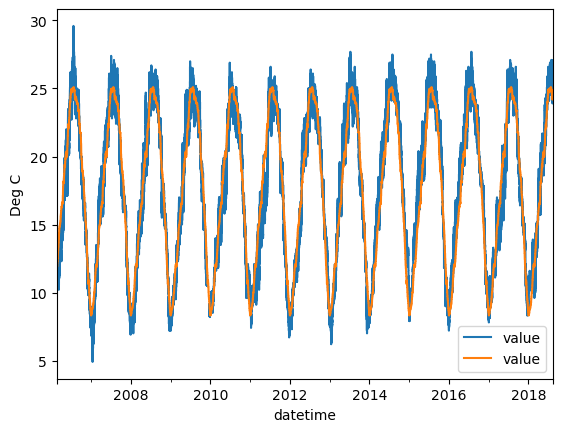

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from vtools import climatology, apply_climatology, climatology_quantiles

df = pd.read_csv("data/mup_temp_2006_2018.csv",index_col=0,parse_dates=[0])  # water temperature time series
clim = climatology(df,freq="day",nsmooth=15) # smooths fortnightly variaiton and higher frequencies
print(clim)
ts_clim = apply_climatology(clim,df.index)

ax=df.plot()
ax.set_ylabel("Deg C")
ts_clim.plot(ax=ax)


##

## Estimating quantiles
The function [climatology_quantiles](../_autosummary/vtools.climatology_quantiles.rst) is still in development (it doesn't handle the beginning or end of the year). It applies quantiles on a daily basis using a window (usually odd numbered for centeredness) to gather statistical strength. 

Text(0, 0.5, 'Deg C')

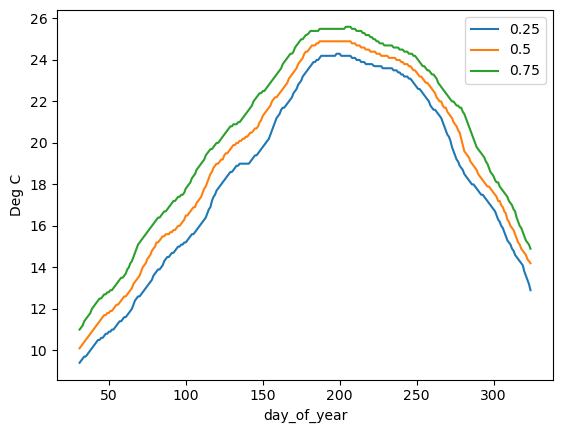

In [45]:

qlim = climatology_quantiles(df, min_day_year=31, max_day_year=325, window_width=21, quantiles=(0.25,0.5,0.75))

qlim.plot()
plt.ylabel("Deg C")

## Sub-hourly climatology
A daily climatology cannot represent the diel (day-night) cycle, which is strong in many series and especially in temperature. An hourly climatology, `freq="hour"`, has 8760 values: one for each hour of a 365-day year (February 29 is ignored). Strength can be gathered from neighboring times in two ways, both wrapping around the end of the year: `nday` pools the same hour on neighboring days (an odd number of days, so `nday=7` is +/- 3 days) and `nsmooth` averages neighboring hours (`nsmooth=3` is +/- 1 hour).

Climatology values are period averages (of a month, day or hour), so applying one at a time step finer than its period requires a choice. This is made with the `substep_interp` argument of [apply_climatology](../_autosummary/vtools.apply_climatology.rst):

* `"fill"` (the default): each time takes the value of the month, day or hour that contains it, a step function. This is what was used above.
* `"linear"`: linear interpolation between the middles of the periods.
* `"rhistinterp"`: a rational histospline that preserves the period averages. Additional arguments such as the tension `p` and `lowbound` are passed through to [rhistinterp](../_autosummary/vtools.rhistinterp.rst).

The example below fits an hourly climatology to ten years of this data (2008-06-01 to 2018-06-01) and applies it at 15 minutes with `rhistinterp`. It then shows how to transition from a historical series to a climatology, as might be needed in a forecast situation. The observations are treated as ending on 2018-08-01 (everything after is set to missing). [transition_ts](../_autosummary/vtools.transition_ts.rst) with `method="blend"` blends the observations into the climatology over 2018-07-26 to 2018-08-01, and the series then continues as climatology. The result is exactly the observations before the blend window and exactly the climatology after it.

In [46]:
import numpy as np
from vtools import transition_ts

ts = pd.read_csv("data/mup_temp_2006_2018.csv",index_col=0,parse_dates=[0])["value"]

# Fit on ten years: 2008-06-01 up to (not including) 2018-06-01
fit = ts[(ts.index >= "2008-06-01") & (ts.index < "2018-06-01")]
hclim = climatology(fit,"hour",nsmooth=3,nday=7)  # +/- 1 hour and +/- 3 days
print(hclim.head())

# Apply at 15 minutes; the hourly values are period averages, which rhistinterp preserves
index15 = pd.date_range("2018-06-01","2018-08-14 08:45",freq="15min")
clim15 = apply_climatology(hclim,index15,substep_interp="rhistinterp",p=2.0)

# Forecast-like situation: observations end at the cutoff, blend into climatology before it
blend_start, cutoff = "2018-07-26", "2018-08-01"
obs = ts["2018-06-01":]
obs_cut = obs.copy()
obs_cut[obs_cut.index > cutoff] = np.nan
spliced = transition_ts(obs_cut,clim15,method="blend",window=(blend_start,cutoff))

hourofyear
1    8.556548
2    8.536310
3    8.519286
4    8.503095
5    8.489881
Name: value, dtype: float64


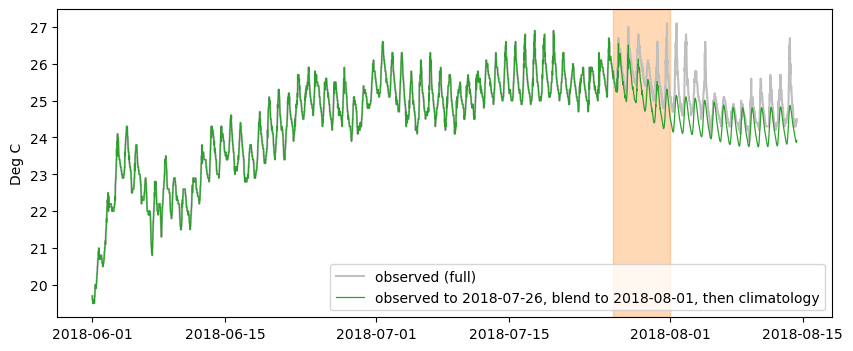

In [47]:
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(obs.index,obs.values,color="0.75",label="observed (full)")
ax.plot(spliced.index,spliced.values,color="tab:green",linewidth=0.9,
        label=f"observed to {blend_start}, blend to {cutoff}, then climatology")
ax.axvspan(pd.Timestamp(blend_start),pd.Timestamp(cutoff),color="tab:orange",alpha=0.3)
ax.set_ylabel("Deg C")
ax.legend(loc="lower right")